# TP3 · Paso 1 — Dataset, EDA y preprocesamiento

**Problema:** predecir si una reserva de GPU será cancelada antes de ejecutarse (`canceled_job`, 1 = cancelada).

En este notebook:
1. Revisión del dataset y detección de **columnas con data leakage**.
2. Limpieza: missing values, valores raros, **duplicados**.
3. Análisis exploratorio y **análisis de cohortes** (`client_type`, `service_tier`, `reserved_gpu_type`).
4. **División train/test** (antes de cualquier transformación que aprenda de los datos) y guardado en `data/`.

Las reglas fijas que salen de acá (columnas a eliminar, features nuevas) quedan en `tp3_comun.py` para reutilizarlas en todos los notebooks y en el predictor.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold

import tp3_comun as C

pd.set_option("display.max_columns", 50)
df = C.cargar_original()
print(df.shape)
df.head()

(47842, 34)


,canceled_job,hours_before_execution,execution_year,execution_month,execution_week,execution_day,peak_gpu_hours,offpeak_gpu_hours,num_primary_processes,num_auxiliary_processes,num_background_processes,service_tier,client_region,client_type,request_channel,returning_client,previous_job_cancellations,successful_previous_jobs,reserved_gpu_type,assigned_gpu_type,resource_modifications,reservation_commitment,orchestration_agent_id,organization_id,queue_wait_time,workload_profile,estimated_cost_per_hour,reserved_storage_units,special_resource_requests,execution_status,execution_status_date,total_processes,total_gpu_hours,high_value_client
0,0,6,2015,7,27,1,0,16,1,0.0,0,priority,PRT,managed_account,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,6.0,NaN,0,single_experiment,0.000,0,0,completed,2015-07-03,1.0,16,0
1,1,88,2015,7,27,1,0,32,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,1,canceled,2015-07-01,2.0,32,0
2,1,92,2015,7,27,1,16,32,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,2,canceled,2015-06-23,2.0,48,0
3,1,79,2015,7,27,2,0,24,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,9.0,NaN,0,single_experiment,3.825,0,1,canceled,2015-06-25,2.0,24,0
4,1,62,2015,7,27,2,16,24,2,0.0,0,standard,PRT,cloud_marketplace,broker_platform,0,0,0,GPU_T1,GPU_T1,0,no_commitment,8.0,NaN,0,single_experiment,3.825,0,1,no_show,2015-07-02,2.0,40,0


## 1. Columnas del CSV vs. diccionario del enunciado

El CSV trae **34 columnas**: el target + las 28 variables documentadas en el enunciado + **5 columnas extra** que no están en el diccionario.

In [2]:
extra = [c for c in df.columns if c not in C.FEATURES_ORIGINALES + [C.TARGET]]
print("Columnas fuera del diccionario:", extra)

Columnas fuera del diccionario: ['execution_status', 'execution_status_date', 'total_processes', 'total_gpu_hours', 'high_value_client']


### 1.1 Data leakage: `execution_status` y `execution_status_date`

`execution_status` es el **estado final** de la reserva y `execution_status_date` la fecha en que se registró ese estado. Son información **posterior** al momento de la predicción.

In [3]:
pd.crosstab(df["execution_status"], df[C.TARGET], margins=True)

canceled_job,0,1,All
execution_status,,,
canceled,0,19416,19416
completed,27887,0,27887
no_show,0,539,539
All,27887,19955,47842


La tabla lo confirma: `canceled` y `no_show` ⇒ `canceled_job = 1`; `completed` ⇒ `canceled_job = 0`. **Es el target escrito de otra forma.** Si las usáramos, el modelo tendría ~100 % de acierto en validación y sería inútil en producción (en el momento de la reserva no sabemos el estado final). **Se eliminan.**

### 1.2 Columnas derivadas no documentadas

In [4]:
suma_horas = (df["peak_gpu_hours"] + df["offpeak_gpu_hours"] == df["total_gpu_hours"]).mean()
suma_proc = (df[["num_primary_processes", "num_auxiliary_processes", "num_background_processes"]]
             .sum(axis=1) == df["total_processes"]).mean()
print(f"total_gpu_hours  == peak + offpeak         : {suma_horas:.2%} de las filas")
print(f"total_processes  == primary + aux + backgr. : {suma_proc:.2%} de las filas")
df.groupby("high_value_client")["estimated_cost_per_hour"].describe()

total_gpu_hours  == peak + offpeak         : 100.00% de las filas
total_processes  == primary + aux + backgr. : 100.00% de las filas


,count,mean,std,min,25%,50%,75%,max
high_value_client,,,,,,,,
0,36525.0,4.548406,1.241393,0.0,3.75,4.55,5.49,6.615
1,11317.0,7.563330,3.244895,0.0,6.84,7.50,8.50,270.000


- `total_gpu_hours` y `total_processes` son **sumas exactas** de otras columnas → las eliminamos del CSV y las **recalculamos nosotros** en `agregar_features()` (así el predictor funciona aunque el set de evaluación no las traiga).
- `high_value_client` no está documentada y se ve que es básicamente un **corte sobre `estimated_cost_per_hour`** (0 ⇒ costo ≤ 6.6; 1 ⇒ costo mayor). No aporta información nueva y no sabemos si estará en los datos de evaluación → **se elimina**.

Nos quedamos con las **28 variables del enunciado**.

In [5]:
X_all = C.limpiar(df)
y_all = df[C.TARGET]
print(X_all.shape)
X_all.dtypes.value_counts()

(47842, 28)


int64      16
str         8
float64     4
Name: count, dtype: int64

## 2. Limpieza

### 2.1 Balance de clases

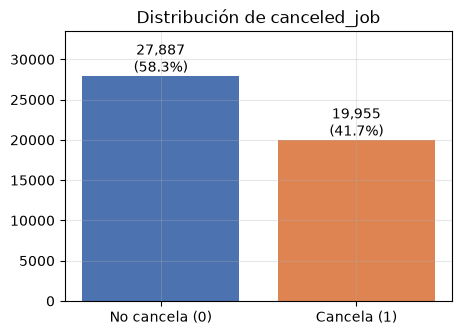

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
vc = y_all.value_counts().sort_index()
ax.bar(["No cancela (0)", "Cancela (1)"], vc.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(vc.values):
    ax.text(i, v, f"{v:,}\n({v/len(y_all):.1%})", ha="center", va="bottom")
ax.set_ylim(0, vc.max() * 1.2); ax.set_title("Distribución de canceled_job")
C.guardar(fig, "01_balance_clases.png"); plt.show()

Desbalance **moderado** (58 / 42). No hace falta sobremuestreo, pero sí elegir métricas que no se dejen engañar por la clase mayoritaria → **Balanced Accuracy** y **ROC-AUC** (se justifican en el notebook 02). Además usaremos `class_weight="balanced"` y validación **estratificada**.

### 2.2 Valores faltantes

In [7]:
na = X_all.isna().sum()
na = na[na > 0].to_frame("faltantes")
na["%"] = 100 * na["faltantes"] / len(X_all)
na["tasa_cancel_si_falta"] = [y_all[X_all[c].isna()].mean() for c in na.index]
na["tasa_cancel_si_no_falta"] = [y_all[X_all[c].notna()].mean() for c in na.index]
na.round(3)

,faltantes,%,tasa_cancel_si_falta,tasa_cancel_si_no_falta
num_auxiliary_processes,1,0.002,1.000,0.417
client_region,20,0.042,0.900,0.417
orchestration_agent_id,5035,10.524,0.331,0.427
organization_id,45540,95.188,0.426,0.235


Decisiones (todas se aplican dentro del pipeline o son reglas fila a fila, sin leakage):

| Variable | % faltante | Decisión | Justificación |
|---|---|---|---|
| `organization_id` | 95 % | Indicador `has_org` + id como categoría (`-1` = sin organización) | Imputar un id no tiene sentido. Que falte **es información**: con organización cancela 24 %, sin ella 43 %. |
| `orchestration_agent_id` | 10.5 % | Indicador `has_agent` + id como categoría (`-1`) | Mismo razonamiento (33 % vs 43 %). |
| `client_region` | 0.04 % | Categoría faltante codificada aparte (`encoded_missing_value`) | Son 20 filas, no vale la pena eliminarlas. |
| `num_auxiliary_processes` | 1 fila | HGB maneja NaN de forma nativa; en modelos lineales, mediana | 1 fila. |

Los ids son **identificadores**: el número no tiene orden, por eso se tratan como categóricos y las categorías con menos de 20 filas se agrupan (`min_frequency=20`) para no sobreajustar a ids raros.

### 2.3 Valores raros / outliers

In [8]:
num = X_all[C.NUM_ORIGINALES].drop(columns=["orchestration_agent_id", "organization_id"])
display(num.describe(percentiles=[.5, .95, .99]).T.round(2))
procesos = X_all[["num_primary_processes", "num_auxiliary_processes", "num_background_processes"]].sum(axis=1)
horas = X_all["peak_gpu_hours"] + X_all["offpeak_gpu_hours"]
print("Reservas con 0 procesos  :", (procesos == 0).sum())
print("Reservas con 0 horas GPU :", (horas == 0).sum())
print("Reservas con costo 0     :", (X_all["estimated_cost_per_hour"] == 0).sum())
print("Costo/hora > 50 USD      :", (X_all["estimated_cost_per_hour"] > 50).sum())

,count,mean,std,min,50%,95%,99%,max
hours_before_execution,47842.0,108.52,109.22,0.0,72.0,332.00,454.0,629.0
execution_year,47842.0,2016.18,0.70,2015.0,2016.0,2017.00,2017.0,2017.0
execution_month,47842.0,6.58,3.09,1.0,7.0,12.00,12.0,12.0
execution_week,47842.0,27.26,13.58,1.0,27.0,49.00,53.0,53.0
execution_day,47842.0,15.67,8.75,1.0,16.0,29.00,31.0,31.0
peak_gpu_hours,47842.0,6.36,7.11,0.0,8.0,16.00,16.0,128.0
offpeak_gpu_hours,47842.0,17.46,11.69,0.0,16.0,40.00,48.0,328.0
num_primary_processes,47842.0,1.84,0.51,0.0,2.0,3.00,3.0,4.0
num_auxiliary_processes,47841.0,0.09,0.37,0.0,0.0,1.00,2.0,3.0
num_background_processes,47842.0,0.00,0.09,0.0,0.0,0.00,0.0,10.0


Reservas con 0 procesos  : 108
Reservas con 0 horas GPU : 193
Reservas con costo 0     : 727
Costo/hora > 50 USD      : 1


- Hay colas largas (`hours_before_execution` hasta 629 h, `estimated_cost_per_hour` hasta 270 USD con p99 = 11) y algunas reservas "vacías" (0 procesos o 0 horas).
- **Decisión: no eliminarlas.** Son pocas (< 1 %), pueden ser reservas reales (p. ej. reservas de prueba que luego se cancelan) y los modelos basados en árboles, que serán la familia principal, son **robustos a outliers** (sólo usan cortes por umbral). Para los modelos lineales se usa `StandardScaler` y su peso es menor.

### 2.4 Duplicados

In [9]:
firma = pd.Series(C.firma_duplicados(X_all))
tam = firma.map(firma.value_counts())
print(f"Filas duplicadas (copias extra)       : {X_all.duplicated().sum():,} ({X_all.duplicated().mean():.1%})")
print(f"Filas que pertenecen a un grupo >= 2  : {(tam >= 2).sum():,}")
print(f"Firmas únicas                         : {firma.nunique():,}")

grupos = pd.DataFrame({"firma": firma, "y": y_all})
pureza = grupos[tam >= 2].groupby("firma")["y"].agg(["mean", "size"])
print(f"Grupos duplicados con etiqueta mixta  : {((pureza['mean'] > 0) & (pureza['mean'] < 1)).sum()} de {len(pureza)}")

bins = pd.cut(tam, [0, 1, 2, 5, 20, 1e9], labels=["1 (única)", "2", "3-5", "6-20", "21+"])
tabla_dup = pd.DataFrame({"y": y_all, "tam": bins}).groupby("tam", observed=True)["y"].agg(["size", "mean"])
tabla_dup.columns = ["filas", "tasa_cancel"]
tabla_dup["%_filas"] = 100 * tabla_dup["filas"] / len(y_all)
tabla_dup.round(3)

Filas duplicadas (copias extra)       : 15,936 (33.3%)
Filas que pertenecen a un grupo >= 2  : 19,435
Firmas únicas                         : 31,906
Grupos duplicados con etiqueta mixta  : 79 de 3499


,filas,tasa_cancel,%_filas
tam,,,
1 (única),28407,0.284,59.377
2,4200,0.357,8.779
3-5,2686,0.378,5.614
6-20,5490,0.646,11.475
21+,7059,0.825,14.755


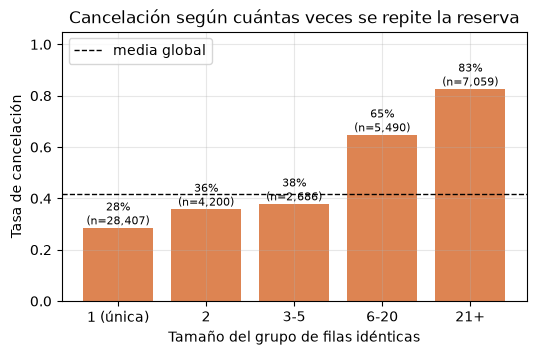

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(tabla_dup.index.astype(str), tabla_dup["tasa_cancel"], color="#DD8452")
for i, (p, n) in enumerate(zip(tabla_dup["tasa_cancel"], tabla_dup["filas"])):
    ax.text(i, p, f"{p:.0%}\n(n={n:,})", ha="center", va="bottom", fontsize=8)
ax.axhline(y_all.mean(), ls="--", c="k", lw=1, label="media global")
ax.set_ylim(0, 1.05); ax.set_xlabel("Tamaño del grupo de filas idénticas"); ax.set_ylabel("Tasa de cancelación")
ax.set_title("Cancelación según cuántas veces se repite la reserva"); ax.legend()
C.guardar(fig, "02_duplicados.png"); plt.show()

**Hallazgo importante:**
- **33 %** de las filas son copias exactas de otra fila (en las 28 variables) y **el 99 % de esos grupos tiene la misma etiqueta**.
- Cuanto más grande el grupo, más se cancela (grupos de 21+ copias: **82 %**). Son reservas "en lote" (mismo cliente, misma fecha, mismo agente), típicas de reservas grupales que se cancelan en bloque.

**Decisión:**
- **No eliminamos los duplicados**: no son errores de carga, son reservas distintas con los mismos atributos y representan la distribución real (si las borramos, cambiamos la tasa de cancelación y el peso de las reservas grupales).
- **Pero sí evitamos el leakage que generan:** si una copia queda en train y otra en validación/test, el modelo "se acuerda" de la respuesta y la métrica sale inflada. Por eso **la división train/test y la validación cruzada se hacen por grupos** (`StratifiedGroupKFold` con la firma de la fila como grupo, visto en la clase 11): todas las copias de una misma reserva caen del mismo lado.

## 3. Análisis exploratorio
### 3.1 Variables numéricas por clase

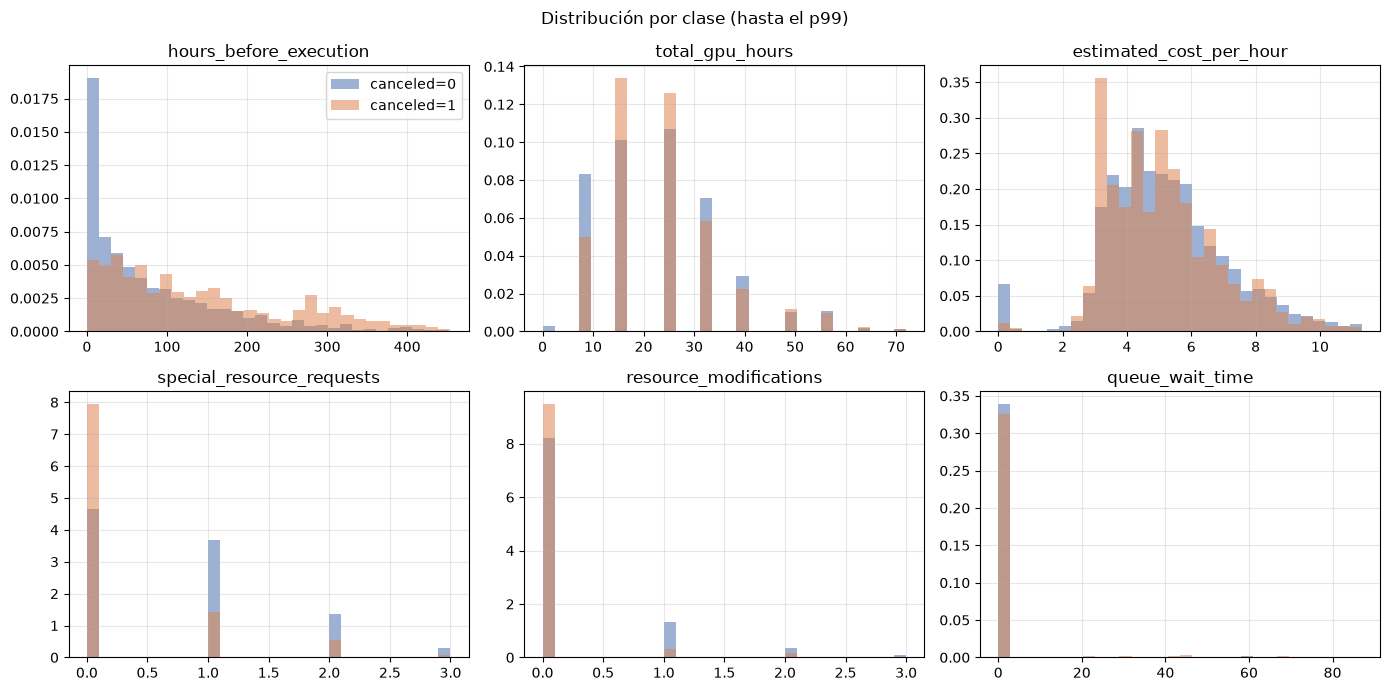

y,0,1
hours_before_execution,50.0,112.000
total_gpu_hours,24.0,24.000
estimated_cost_per_hour,5.0,4.995
special_resource_requests,1.0,0.000
resource_modifications,0.0,0.000
queue_wait_time,0.0,0.000


In [11]:
Xf = C.agregar_features(X_all)
vars_num = ["hours_before_execution", "total_gpu_hours", "estimated_cost_per_hour",
            "special_resource_requests", "resource_modifications", "queue_wait_time"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, vars_num):
    lim = Xf[c].quantile(0.99)
    for clase, col in [(0, "#4C72B0"), (1, "#DD8452")]:
        ax.hist(Xf.loc[(y_all == clase) & (Xf[c] <= lim), c], bins=30, alpha=0.55, density=True,
                color=col, label=f"canceled={clase}")
    ax.set_title(c)
axes[0, 0].legend()
fig.suptitle("Distribución por clase (hasta el p99)"); fig.tight_layout()
C.guardar(fig, "03_numericas_por_clase.png"); plt.show()
Xf.assign(y=y_all).groupby("y")[vars_num].median().T

- **`hours_before_execution`** es la numérica más discriminante: las reservas canceladas se hacen con mucha más anticipación (mediana ~3× mayor). Reservar con mucha antelación da más tiempo para cambiar de planes.
- **`special_resource_requests`** y **`resource_modifications`**: los clientes que piden recursos especiales o modifican la reserva están **más comprometidos** y cancelan menos.
- `queue_wait_time` casi siempre es 0; cuando no lo es, la reserva se cancela más.

### 3.2 Variables categóricas

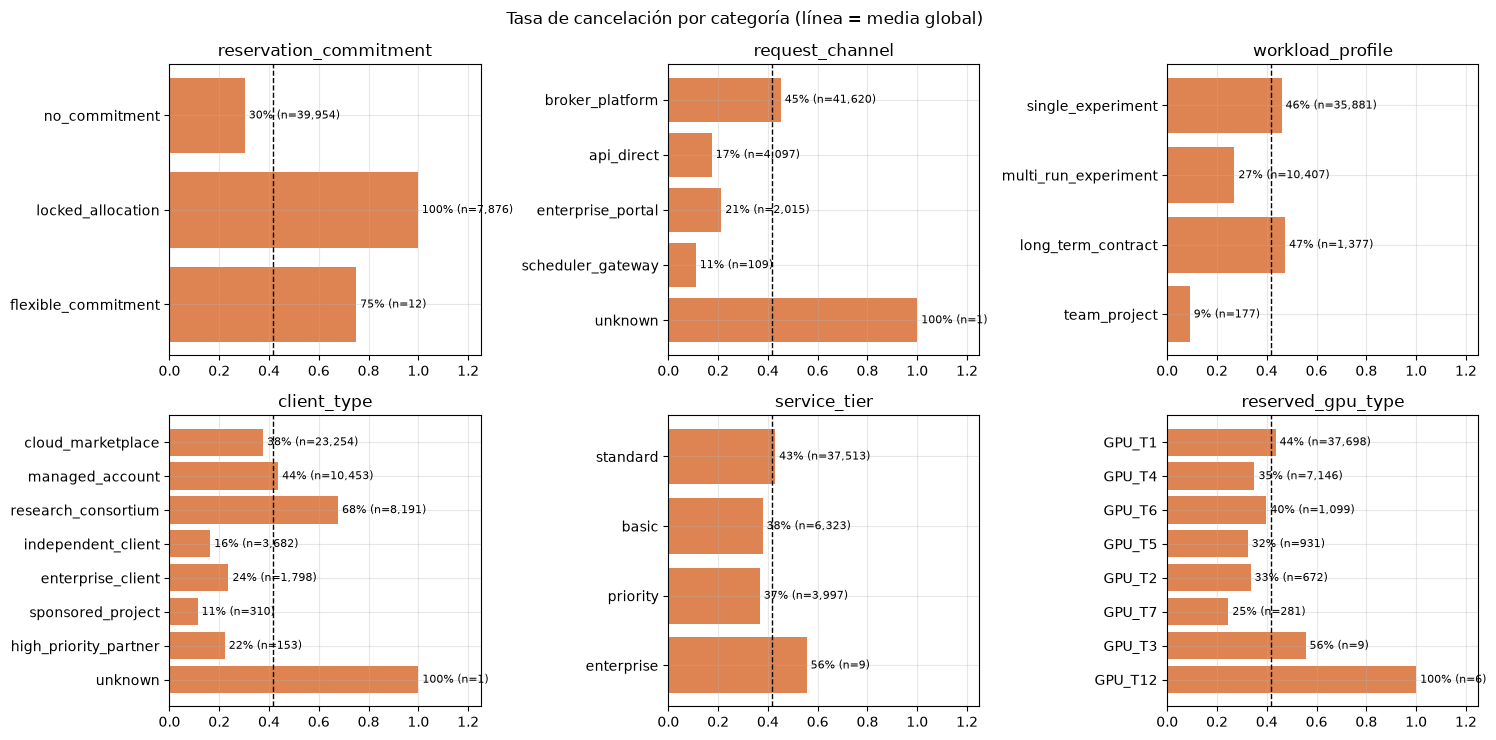

In [12]:
cats = ["reservation_commitment", "request_channel", "workload_profile", "client_type",
        "service_tier", "reserved_gpu_type"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(axes.flat, cats):
    t = y_all.groupby(X_all[c]).agg(["mean", "size"]).sort_values("size", ascending=False).head(8)
    ax.barh(t.index.astype(str)[::-1], t["mean"][::-1], color="#DD8452")
    for i, (m, n) in enumerate(zip(t["mean"][::-1], t["size"][::-1])):
        ax.text(m, i, f" {m:.0%} (n={n:,})", va="center", fontsize=8)
    ax.axvline(y_all.mean(), ls="--", c="k", lw=1); ax.set_xlim(0, 1.25); ax.set_title(c)
fig.suptitle("Tasa de cancelación por categoría (línea = media global)"); fig.tight_layout()
C.guardar(fig, "04_categoricas.png"); plt.show()

In [13]:
for c, titulo in [("gpu_changed", "GPU asignada ≠ reservada"), ("has_org", "Tiene organization_id"),
                  ("returning_client", "Cliente recurrente")]:
    print(titulo); print(y_all.groupby(Xf[c]).agg(["size", "mean"]).round(3), "\n")
top_reg = y_all.groupby(X_all["client_region"]).agg(["size", "mean"]).sort_values("size", ascending=False).head(8)
top_reg.round(3)

GPU asignada ≠ reservada
              size   mean
gpu_changed              
0            43510  0.453
1             4332  0.061 

Tiene organization_id
          size   mean
has_org              
0        45540  0.426
1         2302  0.235 

Cliente recurrente
                   size   mean
returning_client              
0                 46662  0.423
1                  1180  0.193 



,size,mean
client_region,,
PRT,18612,0.652
FRA,5311,0.200
DEU,3783,0.172
GBR,3252,0.296
ESP,2776,0.280
ITA,1926,0.375
BEL,1132,0.201
BRA,1056,0.391


- **`reservation_commitment = locked_allocation`** → **99.8 %** de cancelación: es casi una regla determinística. (En el dominio equivale a un depósito no reembolsable que se usa para reservas especulativas).
- **GPU asignada ≠ GPU reservada** → sólo **6 %** de cancelación. Ojo: la asignación definitiva suele ocurrir cerca de la ejecución, por lo que esta variable podría ser información "del futuro". Como **está en el diccionario del enunciado** como variable disponible, la usamos, pero lo dejamos señalado como riesgo.
- `client_region = PRT` (39 % de los datos) cancela el **65 %**, mucho más que el resto (≈ 20-30 %). Hay 149 regiones; las que tienen < 20 filas se agrupan.
- `request_channel = broker_platform` cancela más que los canales directos.

### 3.3 Análisis de cohortes (`client_type` × `service_tier`, `reserved_gpu_type`)

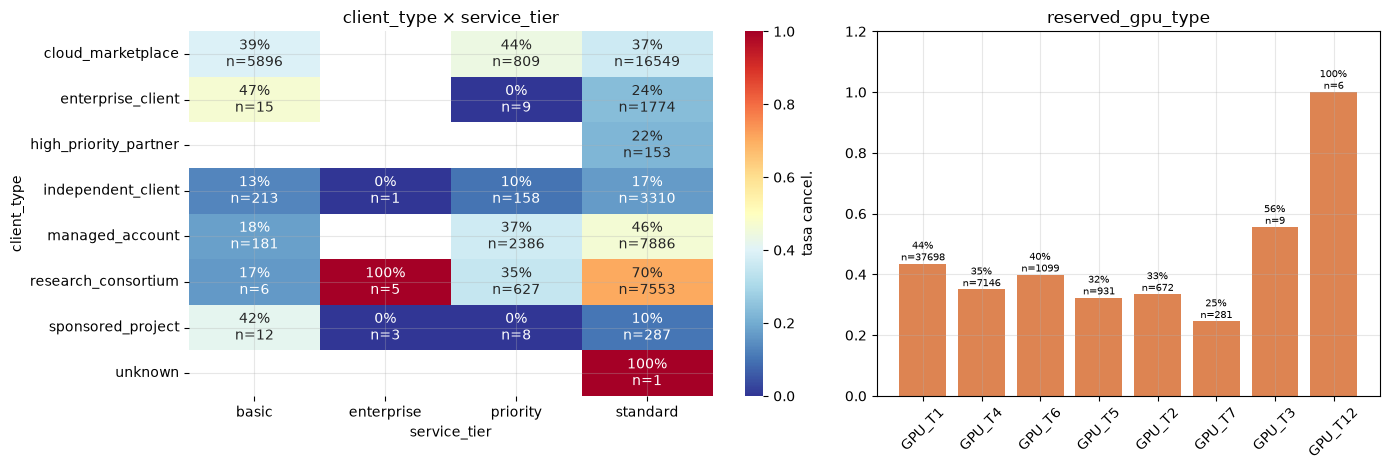

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
tasa = pd.crosstab(X_all["client_type"], X_all["service_tier"], values=y_all, aggfunc="mean")
n = pd.crosstab(X_all["client_type"], X_all["service_tier"])
etiq = tasa.map(lambda v: "" if pd.isna(v) else f"{v:.0%}") + n.map(lambda v: f"\nn={v}" if v else "")
sns.heatmap(tasa, annot=etiq, fmt="", cmap="RdYlBu_r", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "tasa cancel."})
axes[0].set_title("client_type × service_tier")
t = y_all.groupby(X_all["reserved_gpu_type"]).agg(["mean", "size"]).sort_values("size", ascending=False)
axes[1].bar(t.index, t["mean"], color="#DD8452")
for i, (m, k) in enumerate(zip(t["mean"], t["size"])):
    axes[1].text(i, m, f"{m:.0%}\nn={k}", ha="center", va="bottom", fontsize=7)
axes[1].set_ylim(0, 1.2); axes[1].set_title("reserved_gpu_type"); axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout(); C.guardar(fig, "05_cohortes.png"); plt.show()

- **`cloud_marketplace`** (49 % de los datos) tiene una tasa media (38 %): es una cohorte **heterogénea**, ahí esperamos los errores más difíciles.
- **`research_consortium`** + `standard` cancela el 70 %; `independent_client` y `sponsored_project` cancelan poco (10-17 %).
- `service_tier = enterprise` (9 filas), `GPU_T3` (9) y `GPU_T12` (6) son cohortes **diminutas**: cualquier métrica sobre ellas será poco fiable.
- `GPU_T1` concentra el 79 % de las reservas.

### 3.4 Dimensión temporal

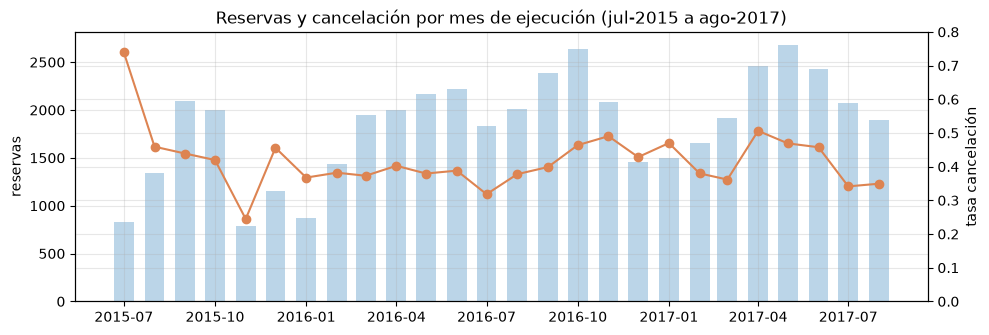

In [15]:
mes = df.groupby(["execution_year", "execution_month"])[C.TARGET].agg(["mean", "size"]).reset_index()
mes["fecha"] = pd.to_datetime(dict(year=mes.execution_year, month=mes.execution_month, day=1))
fig, ax1 = plt.subplots(figsize=(11, 3.5))
ax1.bar(mes["fecha"], mes["size"], width=20, alpha=0.3, label="n reservas")
ax2 = ax1.twinx(); ax2.plot(mes["fecha"], mes["mean"], "o-", c="#DD8452", label="tasa cancel.")
ax1.set_ylabel("reservas"); ax2.set_ylabel("tasa cancelación"); ax2.set_ylim(0, 0.8)
ax1.set_title("Reservas y cancelación por mes de ejecución (jul-2015 a ago-2017)")
C.guardar(fig, "06_temporal.png"); plt.show()

Los datos cubren jul-2015 → ago-2017 con **estacionalidad** (más reservas en primavera/verano) y una tasa de cancelación relativamente estable (35-50 %). No hay un cambio fuerte de distribución en el tiempo, y el set de la competición proviene del mismo período, así que **no usamos split temporal**; sí agregamos variables de calendario (`weekday`, `dayofyear`).

## 4. Features nuevas (reglas fila a fila, en `tp3_comun.agregar_features`)

| Feature | Definición | Por qué |
|---|---|---|
| `total_gpu_hours`, `total_processes` | sumas | tamaño total del job |
| `cost_total` | costo/hora × horas | valor económico de la reserva |
| `cost_per_process` | costo / procesos | precio relativo |
| `gpu_changed` | reservada ≠ asignada | 6 % vs 45 % de cancelación |
| `weekday`, `dayofyear` | calendario de la fecha de ejecución | estacionalidad |
| `has_org`, `has_agent` | indicadores de faltante | el faltante es informativo |
| `prev_cancel_ratio` | cancelaciones previas / jobs previos | historial del cliente |
| `agent`, `org` | ids como categoría | el id no tiene orden numérico |

No aprenden nada de los datos (no usan medias ni el target), por lo que **no generan leakage** y se pueden aplicar igual en train, test y en el predictor. Su utilidad real se mide en el notebook 04 (estrategia de feature engineering).

## 5. División train / test (80 / 20), por grupos de duplicados

Se hace **antes** de cualquier transformación que aprenda de los datos. Usamos el primer fold de un `StratifiedGroupKFold(5)`:
- **estratificado** → misma proporción de cancelaciones en train y test;
- **por grupos** → ninguna reserva duplicada queda repartida entre train y test (si no, el test sobreestimaría el rendimiento sobre reservas nuevas).

In [16]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=C.RANDOM_STATE)
idx_train, idx_test = next(sgkf.split(X_all, y_all, groups=C.firma_duplicados(X_all)))
train = X_all.iloc[idx_train].assign(**{C.TARGET: y_all.iloc[idx_train].values})
test = X_all.iloc[idx_test].assign(**{C.TARGET: y_all.iloc[idx_test].values})

f_tr, f_te = set(C.firma_duplicados(train)), set(C.firma_duplicados(test))
print(f"train: {len(train):,} filas ({len(train)/len(X_all):.1%}) | tasa cancel = {train[C.TARGET].mean():.3f}")
print(f"test : {len(test):,} filas ({len(test)/len(X_all):.1%}) | tasa cancel = {test[C.TARGET].mean():.3f}")
print("Firmas compartidas entre train y test:", len(f_tr & f_te))

C.DATA_DIR.mkdir(exist_ok=True)
train.to_csv(C.DATA_DIR / "train.csv", index=False)
test.to_csv(C.DATA_DIR / "test.csv", index=False)

train: 38,268 filas (80.0%) | tasa cancel = 0.417
test : 9,574 filas (20.0%) | tasa cancel = 0.417
Firmas compartidas entre train y test: 0


## Resumen del paso 1

- **Leakage eliminado:** `execution_status`, `execution_status_date` (son el target). También se quitan las 3 columnas no documentadas (`total_*` se recalculan; `high_value_client` es un corte del costo).
- **Missing:** los faltantes de los ids son informativos → indicadores + categoría `-1`.
- **Outliers:** se conservan (pocos, plausibles y los árboles son robustos).
- **Duplicados:** 33 % de las filas. Se conservan pero **todas las particiones se hacen por grupos** para evitar leakage.
- **EDA:** las variables más fuertes son `reservation_commitment`, `hours_before_execution`, `client_region`, `gpu_changed`, `special_resource_requests`, `client_type`, `request_channel`.
- **Cohortes:** `cloud_marketplace` es grande y heterogénea (candidata a concentrar errores); hay cohortes diminutas (`enterprise`, `GPU_T3`, `GPU_T12`).
- **Split:** 80/20 estratificado por grupos → `data/train.csv` y `data/test.csv`. El test no se vuelve a tocar hasta el notebook 05.